# Shape-only normalising factors, 2-fish newest table, grouped by the pair that set them

Run: `eod_assignment_control_groups.py --rec 2-fish` → `results/eod_ground_truth/conductivities/my_model_shape_synch_fix_newest.csv`
(every EOD of `Data_2fish_2024-02-13T14_33_21_synch_fix_newest.csv`, its own frame, ZEUS masks, BEM conductivities, sink at the
tail tip). Fish 1 is the emitter (ground truth); fish 0 is silent.

Per EOD:
- recorded peak pattern $r$ (V; each pair demeaned, at the sample where |V| peaks over the pairs); **$r_{norm} = \max_p |r_p|$**;
- unit-current model pattern of each fish $u_f$ (before the × −1); **$u_{f,norm} = \max_p |u_{f,p}|$**;
- shape only compares $r / r_{norm}$ with $-u_f / u_{f,norm}$, so these two factors are what it divides out.

**Deciding pair**: the pair where the maximum is, $\arg\max_p |r_p|$ for the recording and $\arg\max_p |u_{f,p}|$ for fish f's model.

Groups: all EODs; **clean good** (newest QC: mask QC, Denis' SLEAP-good rule and the 0.8 × median mask-length limit,
`eod_clean_good_synch_fix_newest.csv`). Correct = shape only picked fish 1.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
%matplotlib inline

RES = 'results/eod_ground_truth'
OUT = f'{RES}/conductivities/normalizing_factors_newest'; os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
GRP_COL = {'all EODs': '#85857F', 'clean good': '#1F5FBF'}
PAIRS = range(1, 11)

d = pd.read_csv(f'{RES}/conductivities/my_model_shape_synch_fix_newest.csv')
cg = pd.read_csv(f'{RES}/eod_clean_good_synch_fix_newest.csv')
assert (cg.Frame.to_numpy() == d.Frame.to_numpy()).all()
r = d[[f'r_raw_p{p}' for p in PAIRS]].to_numpy()
u = {f: d[[f'u{f}_raw_p{p}' for p in PAIRS]].to_numpy() for f in (0, 1)}
i = np.arange(len(d))
T = pd.DataFrame({'eod_row': d.eod_row, 'Frame': d.Frame, 'clean good': cg.clean_good.to_numpy(),
                  'correct': (d.pick == 1).to_numpy(), 'r_norm': d.r_norm, 'r pair': np.abs(r).argmax(1) + 1,
                  'r sign at its pair': np.sign(r[i, np.abs(r).argmax(1)])})
for f in (0, 1):
    ok = d[f'fish_ok_{f}'].to_numpy(bool)
    T[f'u{f}_norm'] = np.where(ok, d[f'u{f}_norm'], np.nan)
    T[f'u{f} pair'] = np.where(ok, np.nanargmax(np.abs(np.nan_to_num(u[f], nan=-1)), 1) + 1, 0)
    T[f'-u{f} sign at its pair'] = np.where(ok, -np.sign(u[f][i, np.abs(np.nan_to_num(u[f])).argmax(1)]), np.nan)
T['same pair (r, fish 1)'] = T['r pair'] == T['u1 pair']
T['r_norm / u1_norm'] = T.r_norm / T.u1_norm                                   # the per-EOD scale shape only divides out
assert np.allclose(T.r_norm, np.abs(r).max(1))
T.to_csv(f'{OUT}/normalizing_factors_per_eod.csv', index=False)
GRPS = {'all EODs': np.ones(len(T), bool), 'clean good': T['clean good'].to_numpy()}
print(f"{len(T)} EODs, clean good {T['clean good'].sum()}; fish 1 modelled in {T.u1_norm.notna().sum()}, fish 0 in {T.u0_norm.notna().sum()}")
print(f"recorded max pair = fish 1's model max pair: all {T['same pair (r, fish 1)'].mean() * 100:.1f}%, "
      f"clean good {T.loc[T['clean good'], 'same pair (r, fish 1)'].mean() * 100:.1f}%")

18801 EODs, clean good 3536; fish 1 modelled in 18796, fish 0 in 18646
recorded max pair = fish 1's model max pair: all 82.0%, clean good 82.8%


## Which pair sets the maximum, and how big it is

In [2]:
def summary(col, pair_col, m):
    g = T[m & T[col].notna()].groupby(pair_col)[col]
    s = g.describe(percentiles=[0.1, 0.5, 0.9])[['count', '10%', '50%', '90%']]
    s['count'] = s['count'].astype(int); s['% of EODs'] = 100 * s['count'] / s['count'].sum()
    return s.reindex(PAIRS)

tabs = {}
for grp, m in GRPS.items():
    for col, pc, nm in (('r_norm', 'r pair', 'recorded r_norm (V)'), ('u1_norm', 'u1 pair', 'fish 1 (emitter) u1_norm'),
                        ('u0_norm', 'u0 pair', 'fish 0 (silent) u0_norm')):
        tabs[(grp, nm)] = summary(col, pc, m)
TAB = pd.concat(tabs, names=['EODs', 'factor', 'deciding pair']); TAB.to_csv(f'{OUT}/normalizing_factors_by_pair.csv')
for grp in GRPS:
    print(f'--- {grp}'); display(pd.concat({k[1]: v for k, v in tabs.items() if k[0] == grp}, axis=1).round(4))

--- all EODs


recorded r_norm (V)                                    \
                 count     10%     50%     90% % of EODs   
1                 3760  0.0972  0.1717  0.2332   19.9989   
2                 1667  0.0686  0.1178  0.2201    8.8665   
3                  768  0.0524  0.1449  0.2470    4.0849   
4                  653  0.0785  0.1486  0.2189    3.4732   
5                   90  0.0583  0.1617  0.2628    0.4787   
6                 1874  0.0910  0.2493  0.3230    9.9676   
7                 2536  0.1180  0.2634  0.3516   13.4886   
8                 4230  0.0970  0.2202  0.3306   22.4988   
9                 1992  0.0579  0.2287  0.3760   10.5952   
10                1231  0.0433  0.0881  0.3990    6.5475   

   fish 1 (emitter) u1_norm                                    \
                      count     10%     50%     90% % of EODs   
1                      3856  0.1673  0.4209  0.4612   20.5150   
2                      1561  0.1279  0.2141  0.4069    8.3050   
3                       571  0.1361  0.3173  0.4476    3.0379   
4                       607  0.1686  0.3395  0.4550    3.2294   
5                       382  0.1596  0.3499  0.4926    2.0323   
6                      1624  0.1335  0.3457  0.4866    8.6401   
7                      2456  0.1677  0.3923  0.5439   13.0666   
8                      3716  0.1423  0.3343  0.4917   19.7702   
9                      2371  0.0947  0.3449  0.5645   12.6144   
10                     1652  0.0915  0.1716  0.4647    8.7891   

   fish 0 (silent) u0_norm                                    
                     count     10%     50%     90% % of EODs  
1                     2199  0.0919  0.2382  0.3239   11.7934  
2                     2600  0.1481  0.3116  0.4719   13.9440  
3                     1141  0.0979  0.2257  0.3259    6.1193  
4                      791  0.1193  0.2617  0.3779    4.2422  
5                     1170  0.1353  0.3315  0.4342    6.2748  
6                     1469  0.0967  0.2452  0.3627    7.8784  
7                     1500  0.0866  0.2043  0.3607    8.0446  
8                     2209  0.0908  0.2281  0.3569   11.8470  
9                     2157  0.0703  0.1221  0.4614   11.5682  
10                    3410  0.0865  0.2986  0.4428   18.2881

--- clean good


recorded r_norm (V)                                    \
                 count     10%     50%     90% % of EODs   
1                  275  0.0893  0.1482  0.2123    7.7771   
2                  579  0.0858  0.1093  0.1778   16.3744   
3                   77  0.0630  0.1313  0.2961    2.1776   
4                   87  0.0850  0.1589  0.2264    2.4604   
5                   19  0.1637  0.2067  0.2883    0.5373   
6                  601  0.1230  0.2662  0.3136   16.9966   
7                  606  0.1243  0.2708  0.3421   17.1380   
8                  595  0.0969  0.2192  0.2939   16.8269   
9                  482  0.0645  0.2173  0.3280   13.6312   
10                 215  0.0499  0.1256  0.3394    6.0803   

   fish 1 (emitter) u1_norm                                    \
                      count     10%     50%     90% % of EODs   
1                       341  0.1605  0.3410  0.4401    9.6437   
2                       556  0.1614  0.2092  0.3628   15.7240   
3                        82  0.1521  0.2703  0.4329    2.3190   
4                        78  0.2848  0.4233  0.5250    2.2059   
5                       120  0.2949  0.4264  0.5036    3.3937   
6                       502  0.1946  0.3904  0.4983   14.1968   
7                       602  0.1925  0.4431  0.5519   17.0249   
8                       516  0.1613  0.3835  0.4838   14.5928   
9                       406  0.1284  0.4327  0.5678   11.4819   
10                      333  0.1055  0.1620  0.4712    9.4174   

   fish 0 (silent) u0_norm                                    
                     count     10%     50%     90% % of EODs  
1                      457  0.1427  0.2781  0.3183   12.9242  
2                      656  0.2213  0.3011  0.4134   18.5520  
3                      187  0.1278  0.2543  0.3292    5.2885  
4                      163  0.1508  0.3412  0.4392    4.6097  
5                      249  0.1588  0.3652  0.4466    7.0419  
6                      211  0.1056  0.3083  0.3940    5.9672  
7                      169  0.0887  0.1685  0.3369    4.7794  
8                      264  0.1182  0.2449  0.3414    7.4661  
9                      724  0.0978  0.4003  0.4800   20.4751  
10                     456  0.0930  0.2849  0.4363   12.8959

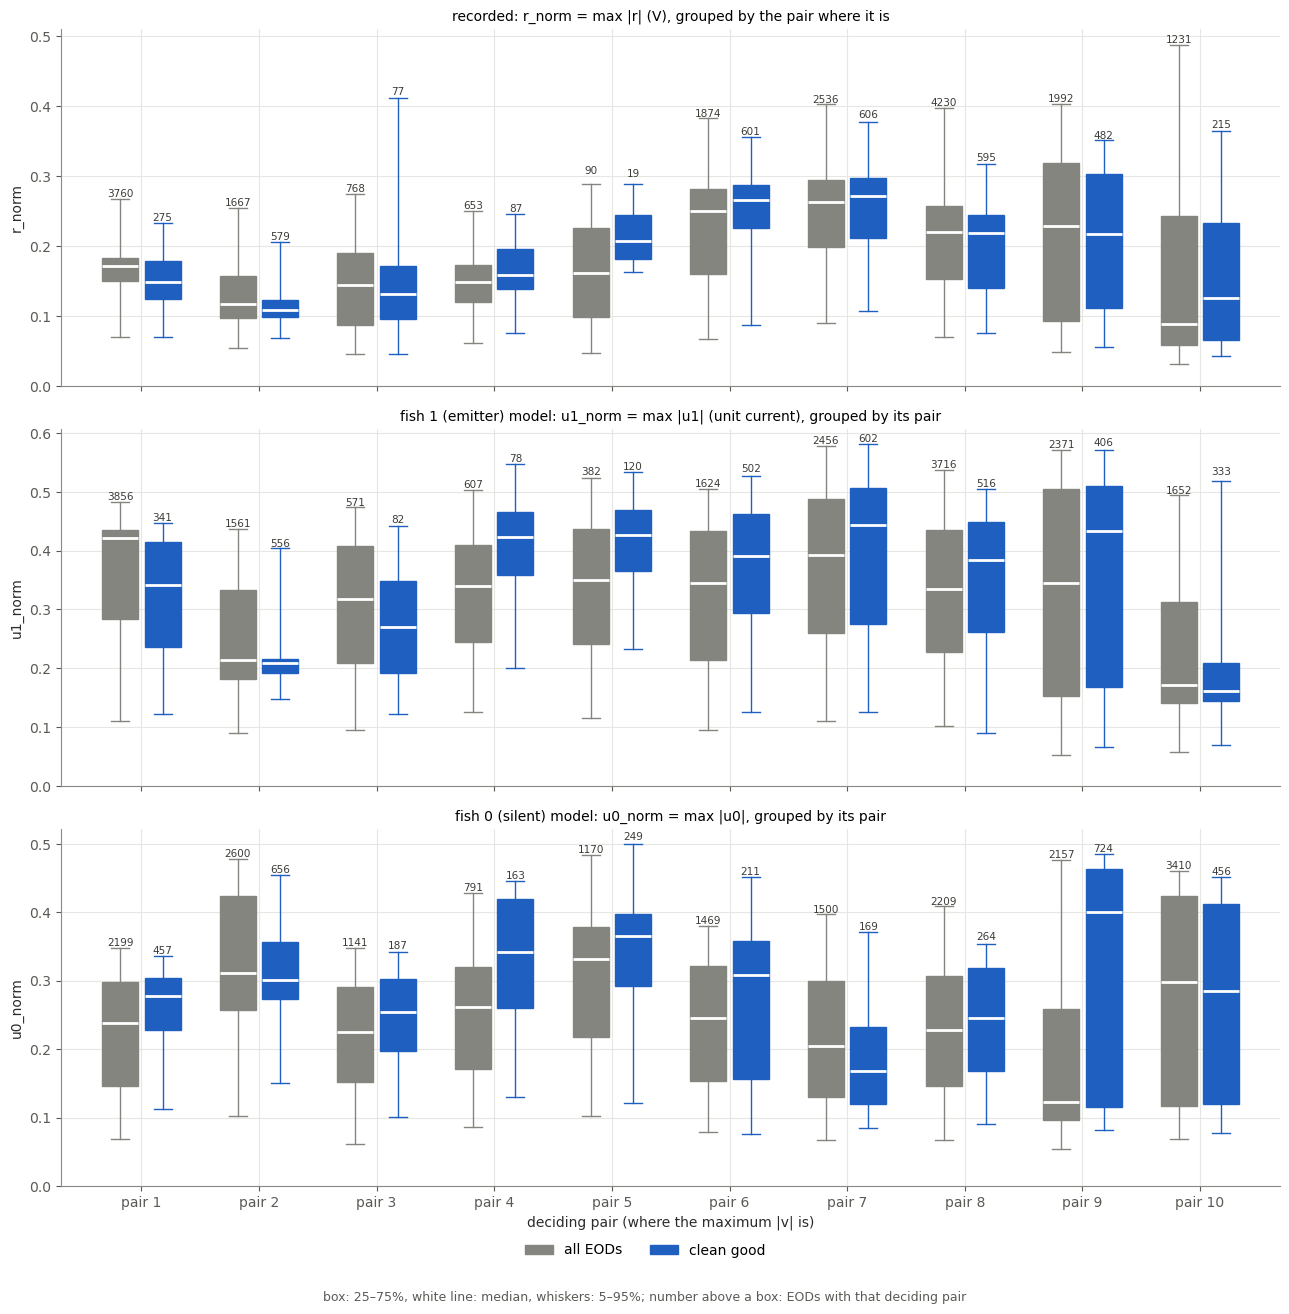

In [3]:
fig, axs = plt.subplots(3, 1, figsize=(13, 12.5), sharex=True)
x = np.array(list(PAIRS)); w = 0.36
for ax, (col, pc, ttl) in zip(axs, (('r_norm', 'r pair', 'recorded: r_norm = max |r| (V), grouped by the pair where it is'),
                                    ('u1_norm', 'u1 pair', 'fish 1 (emitter) model: u1_norm = max |u1| (unit current), grouped by its pair'),
                                    ('u0_norm', 'u0 pair', 'fish 0 (silent) model: u0_norm = max |u0|, grouped by its pair'))):
    for k, (grp, m) in enumerate(GRPS.items()):
        data = [T.loc[m & (T[pc] == p), col].dropna().to_numpy() for p in PAIRS]
        pos = x + (k - 0.5) * w; has = [len(v) > 0 for v in data]
        ax.boxplot([v for v in data if len(v)], positions=pos[has], widths=w * 0.85, whis=(5, 95), showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor=GRP_COL[grp], edgecolor=GRP_COL[grp]), medianprops=dict(color='white', lw=2),
                   whiskerprops=dict(color=GRP_COL[grp]), capprops=dict(color=GRP_COL[grp]))
        for p_, v in zip(pos, data):
            if len(v): ax.text(p_, np.percentile(v, 95), f'{len(v)}', ha='center', va='bottom', fontsize=7.5, color='#3a3a36')
    ax.set(ylim=(0, None), ylabel=col); ax.set_title(ttl, fontsize=10)
axs[-1].set(xticks=x, xticklabels=[f'pair {p}' for p in PAIRS], xlabel='deciding pair (where the maximum |v| is)')
fig.legend(handles=[Patch(color=c, label=g) for g, c in GRP_COL.items()], loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.text(0.5, -0.045, 'box: 25–75%, white line: median, whiskers: 5–95%; number above a box: EODs with that deciding pair', ha='center', fontsize=9, color='#5a5a55')
plt.tight_layout(); fig.savefig(f'{OUT}/normalizing_factors_by_pair.png', dpi=110, bbox_inches='tight'); plt.show()

## Does the recording's deciding pair match the emitter model's?

Rows: the pair with the largest recorded |v|; columns: the pair with the largest |v| in fish 1's model (% of each row).

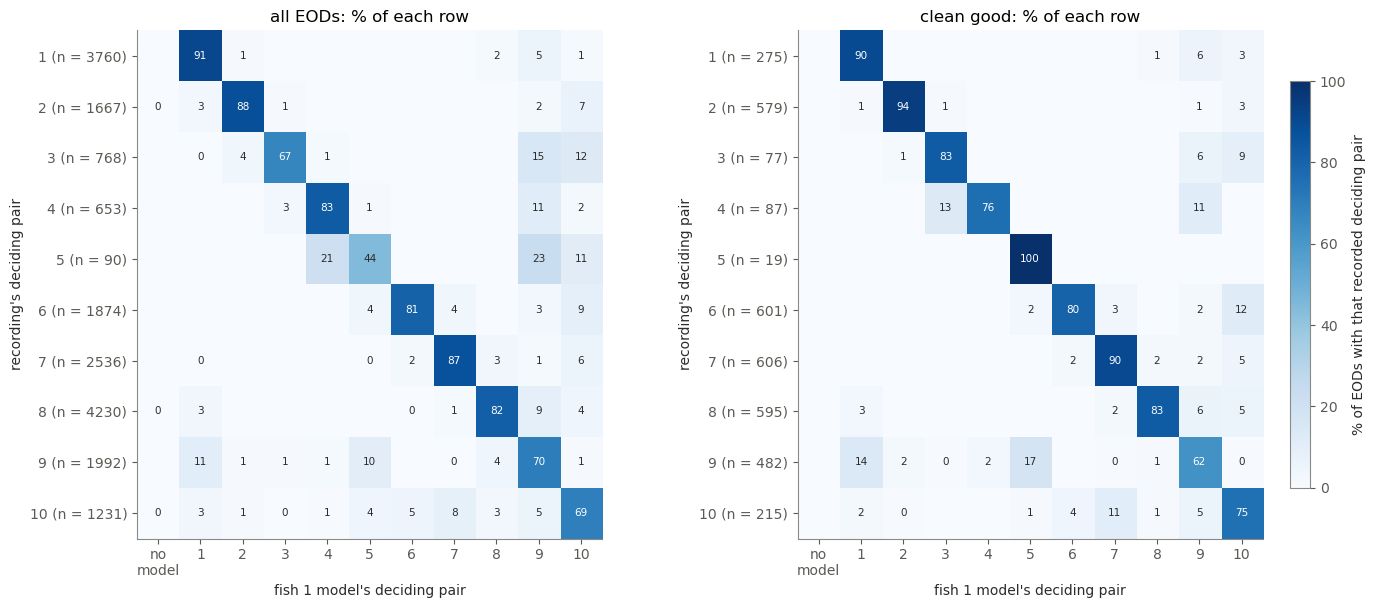

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(17.5, 6.6), gridspec_kw=dict(wspace=0.42))
for ax, (grp, m) in zip(axs, GRPS.items()):
    ct = pd.crosstab(T.loc[m, 'r pair'], T.loc[m, 'u1 pair']).reindex(index=PAIRS, columns=[0] + list(PAIRS), fill_value=0)
    pct = 100 * ct.div(ct.sum(1).replace(0, np.nan), axis=0)
    im = ax.imshow(pct.to_numpy(), cmap='Blues', vmin=0, vmax=100, aspect='auto')
    for a_ in range(pct.shape[0]):
        for b_ in range(pct.shape[1]):
            v = pct.iat[a_, b_]
            if np.isfinite(v) and ct.iat[a_, b_] > 0:
                ax.text(b_, a_, f'{v:.0f}', ha='center', va='center', fontsize=7.5, color='white' if v > 60 else '#2b2b2b')
    ax.set(xticks=range(11), xticklabels=['no\nmodel'] + [str(p) for p in PAIRS], yticks=range(10),
           yticklabels=[f'{p} (n = {ct.loc[p].sum()})' for p in PAIRS], xlabel="fish 1 model's deciding pair",
           ylabel="recording's deciding pair", title=f'{grp}: % of each row'); ax.grid(False)
fig.colorbar(im, ax=axs, shrink=0.8, pad=0.02, label='% of EODs with that recorded deciding pair')
fig.savefig(f'{OUT}/deciding_pair_recorded_vs_model.png', dpi=110, bbox_inches='tight'); plt.show()

## The scale shape only divides out: $r_{norm} / u_{1,norm}$

For EODs where the recording and fish 1's model peak at the same pair, $r_{norm}/u_{1,norm}$ is the gain (V per model unit) that
pair would need for that EOD; grouped by that pair, correct and wrong picks separately.

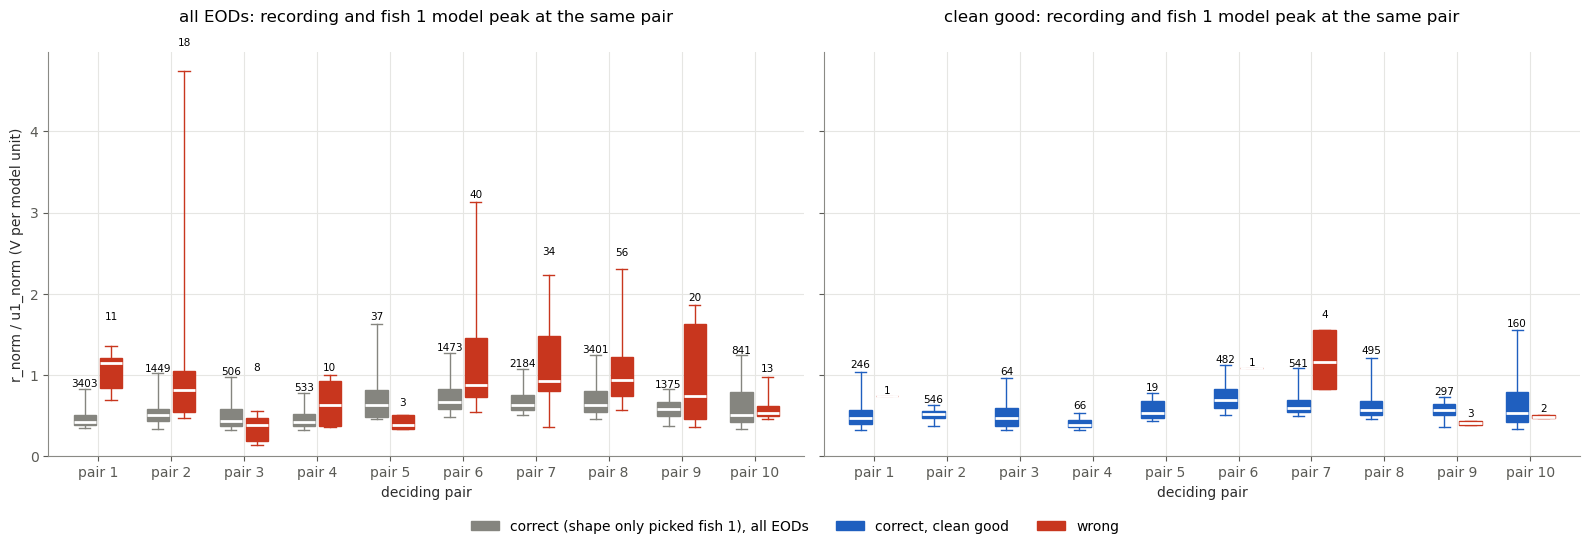

,count,10%,50%,90%,90% / 10%
r pair,,,,,
1,3403.0,0.369,0.420,0.687,1.862
2,1449.0,0.370,0.512,0.812,2.193
3,506.0,0.340,0.438,0.807,2.377
4,533.0,0.337,0.424,0.698,2.070
5,37.0,0.470,0.637,1.538,3.270
6,1473.0,0.522,0.671,1.102,2.112
7,2184.0,0.526,0.638,0.928,1.763
8,3401.0,0.495,0.639,1.042,2.107
9,1375.0,0.392,0.587,0.759,1.936


In [5]:
same = T['same pair (r, fish 1)'].to_numpy()
fig, axs = plt.subplots(1, 2, figsize=(16, 5.2), sharey=True)
for ax, (grp, m) in zip(axs, GRPS.items()):
    for k, (lab, mm_, c) in enumerate((('correct', T.correct.to_numpy(), GRP_COL[grp]), ('wrong', ~T.correct.to_numpy(), '#C8361E'))):
        data = [T.loc[m & same & mm_ & (T['r pair'] == p), 'r_norm / u1_norm'].dropna().to_numpy() for p in PAIRS]
        pos = x + (k - 0.5) * w; has = [len(v) > 0 for v in data]
        if any(has):
            ax.boxplot([v for v in data if len(v)], positions=pos[has], widths=w * 0.85, whis=(5, 95), showfliers=False, patch_artist=True,
                       boxprops=dict(facecolor=c, edgecolor=c), medianprops=dict(color='white', lw=2), whiskerprops=dict(color=c), capprops=dict(color=c))
        for p_, v in zip(pos, data):
            if len(v): ax.text(p_, np.percentile(v, 95), f'{len(v)}', ha='center', va='bottom', fontsize=7.5)
    ax.set(xticks=x, xticklabels=[f'pair {p}' for p in PAIRS], ylim=(0, None), xlabel='deciding pair')
    ax.set_title(f'{grp}: recording and fish 1 model peak at the same pair', pad=22)
axs[0].set_ylabel('r_norm / u1_norm (V per model unit)')
fig.legend(handles=[Patch(color='#85857F', label='correct (shape only picked fish 1), all EODs'), Patch(color='#1F5FBF', label='correct, clean good'),
                    Patch(color='#C8361E', label='wrong')], loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(); fig.savefig(f'{OUT}/scale_ratio_by_pair.png', dpi=110, bbox_inches='tight'); plt.show()
R = T[same & T.correct].groupby('r pair')['r_norm / u1_norm'].describe(percentiles=[0.1, 0.5, 0.9])[['count', '10%', '50%', '90%']].reindex(PAIRS)
R['90% / 10%'] = R['90%'] / R['10%']; R.to_csv(f'{OUT}/scale_ratio_by_pair_correct.csv'); display(R.round(3))

## Normalising ratio per deciding pair, every EOD as a point

**Normalising ratio** = $r_{norm} / u_{1,norm}$: the recording's normalising constant over the true emitter's (fish 1) normalising
constant, i.e. how much fish 1's unit-current model had to be scaled to match the recording when both were brought to max |v| = 1.
Only EODs where **both maxima are on the same pair** (so the scaling was set on one pair), grouped by that pair.

Each dot is one EOD (horizontal jitter only for visibility): grey = shape only picked fish 1, red = it picked fish 0. Black bar:
mean with ± 1 SD; white diamond: median. Above each pair: n, mean, and the coefficient of variation (SD / mean).

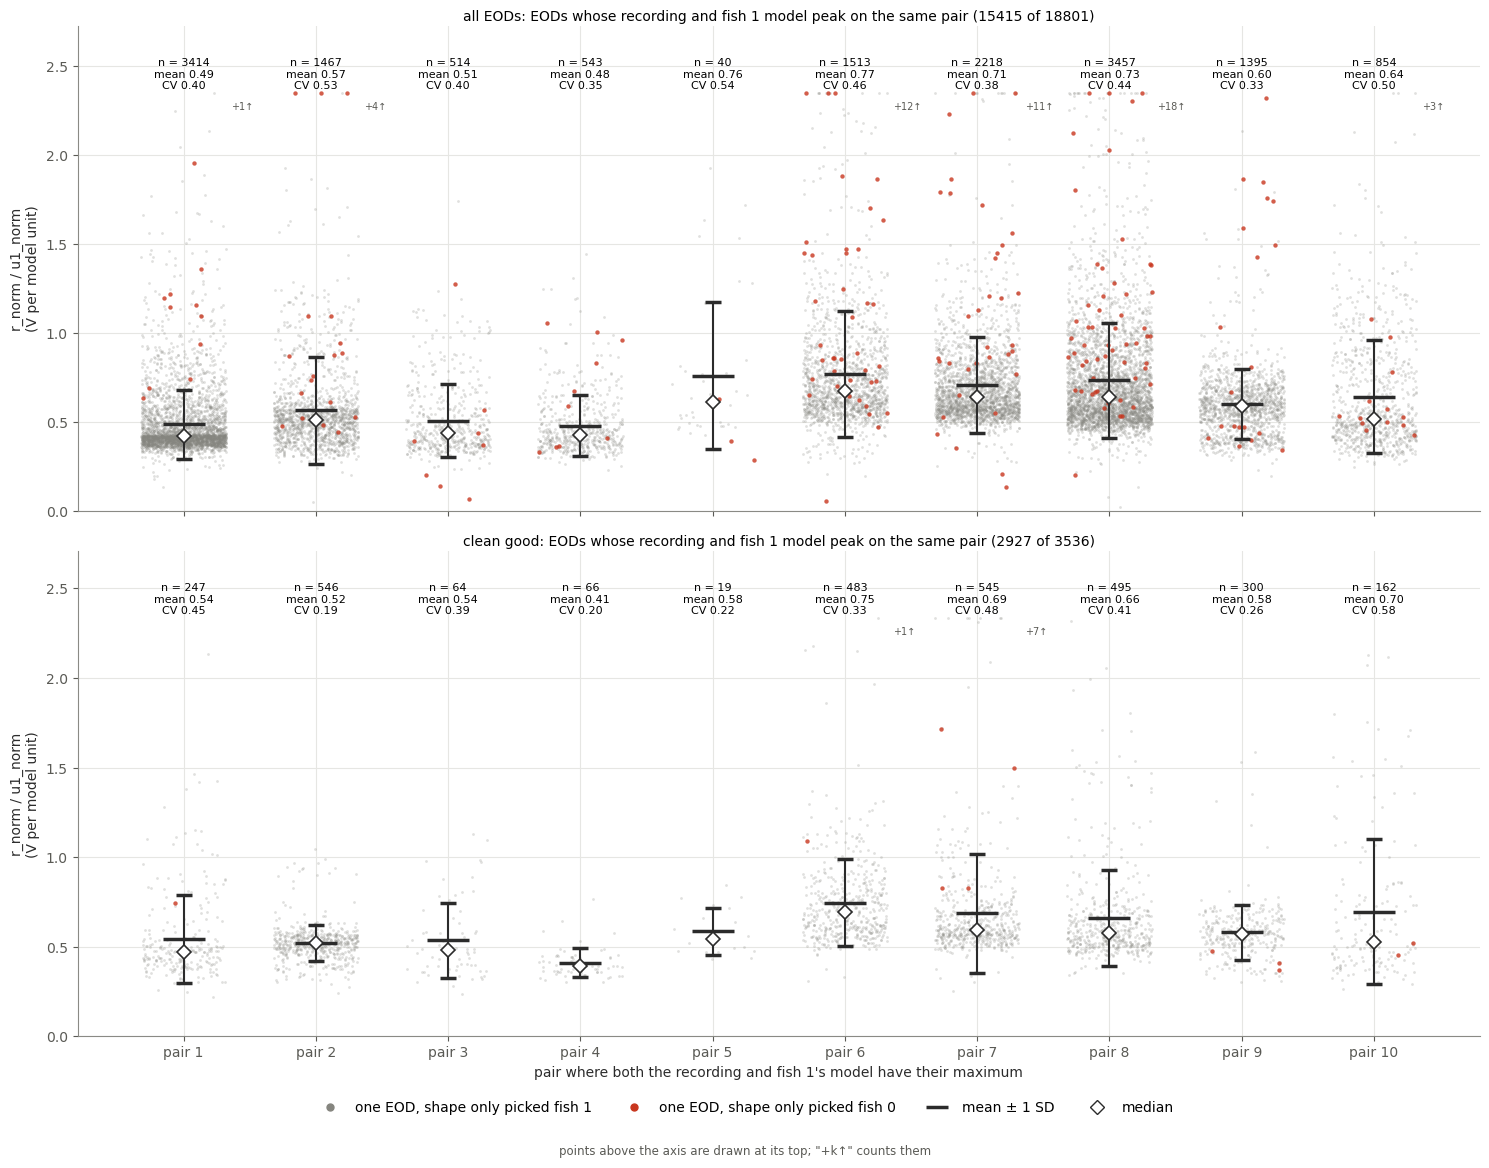

all EODs


,n,mean,sd,median,q10,q90,cv,wrong picks,90% / 10%
pair,,,,,,,,,
1,3414,0.488,0.194,0.420,0.369,0.692,0.397,11,1.875
2,1467,0.566,0.302,0.513,0.371,0.835,0.533,18,2.251
3,514,0.508,0.205,0.438,0.338,0.808,0.403,8,2.389
4,543,0.481,0.170,0.425,0.337,0.707,0.353,10,2.097
5,40,0.761,0.414,0.613,0.461,1.535,0.544,3,3.334
6,1513,0.771,0.355,0.675,0.522,1.121,0.460,40,2.146
7,2218,0.708,0.270,0.639,0.526,0.935,0.381,34,1.778
8,3457,0.734,0.322,0.641,0.495,1.052,0.439,56,2.123
9,1395,0.602,0.197,0.588,0.392,0.767,0.328,20,1.955


clean good


,n,mean,sd,median,q10,q90,cv,wrong picks,90% / 10%
pair,,,,,,,,,
1,247,0.543,0.244,0.471,0.359,0.861,0.450,1,2.396
2,546,0.520,0.101,0.519,0.404,0.597,0.193,0,1.477
3,64,0.536,0.211,0.479,0.335,0.856,0.394,0,2.554
4,66,0.410,0.081,0.391,0.334,0.487,0.197,0,1.457
5,19,0.585,0.130,0.541,0.463,0.772,0.222,0,1.665
6,483,0.746,0.243,0.693,0.539,1.030,0.327,1,1.911
7,545,0.686,0.331,0.592,0.514,0.891,0.482,4,1.735
8,495,0.659,0.267,0.574,0.476,0.915,0.405,0,1.923
9,300,0.579,0.152,0.569,0.413,0.703,0.262,3,1.702


all same-pair EODs pooled: mean 0.630, SD 0.294, CV 0.47; share of the variance between pairs (one-way, between-pair SS / total SS): 13.3%


In [6]:
SEL = T[same & T['r_norm / u1_norm'].notna()].copy()
rng = np.random.default_rng(0)
def stats(v):
    return dict(n=len(v), mean=v.mean(), sd=v.std(ddof=1) if len(v) > 1 else np.nan, median=np.median(v),
                q10=np.percentile(v, 10), q90=np.percentile(v, 90))
rows = []
fig, axs = plt.subplots(2, 1, figsize=(15, 11), sharex=True)
for ax, (grp, m) in zip(axs, GRPS.items()):
    sub = SEL[m[SEL.index]]
    ymax = np.percentile(sub['r_norm / u1_norm'], 99.5) * 1.1
    for p in PAIRS:
        s_ = sub[sub['r pair'] == p]
        if s_.empty: continue
        v = s_['r_norm / u1_norm'].to_numpy(); ok = s_.correct.to_numpy()
        jx = p + rng.uniform(-0.32, 0.32, len(v))
        ax.scatter(jx[ok], np.minimum(v[ok], ymax), s=4, alpha=0.25, color='#85857F', lw=0, zorder=2)
        ax.scatter(jx[~ok], np.minimum(v[~ok], ymax), s=10, alpha=0.8, color='#C8361E', lw=0, zorder=3)
        st = stats(v); rows.append(dict(EODs=grp, pair=p, **st, cv=st['sd'] / st['mean'], **{'wrong picks': int((~ok).sum())}))
        ax.errorbar(p, st['mean'], yerr=st['sd'], fmt='_', ms=30, mew=2.5, color='#2b2b2b', capsize=6, lw=1.5, zorder=5)
        ax.plot(p, st['median'], 'D', ms=7, mfc='white', mec='#2b2b2b', mew=1.2, zorder=6)
        ax.text(p, ymax * 1.005, f"n = {st['n']}\nmean {st['mean']:.2f}\nCV {st['sd'] / st['mean']:.2f}", ha='center', va='bottom', fontsize=8)
        above = (v > ymax).sum()
        if above: ax.text(p + 0.36, ymax * 0.98, f'+{above}↑', fontsize=7, color='#5a5a55', va='top')
    ax.set(ylim=(0, ymax * 1.16), ylabel='r_norm / u1_norm\n(V per model unit)')
    ax.set_title(f'{grp}: EODs whose recording and fish 1 model peak on the same pair ({len(sub)} of {int(m.sum())})', fontsize=10, pad=4)
axs[-1].set(xticks=list(PAIRS), xticklabels=[f'pair {p}' for p in PAIRS], xlabel='pair where both the recording and fish 1\'s model have their maximum')
h = [Line2D([], [], marker='o', ls='', ms=5, color='#85857F', label='one EOD, shape only picked fish 1'),
     Line2D([], [], marker='o', ls='', ms=5, color='#C8361E', label='one EOD, shape only picked fish 0'),
     Line2D([], [], marker='_', ls='', ms=16, mew=2.5, color='#2b2b2b', label='mean ± 1 SD'),
     Line2D([], [], marker='D', ls='', ms=7, mfc='white', mec='#2b2b2b', label='median')]
fig.legend(handles=h, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.03))
fig.text(0.5, -0.055, 'points above the axis are drawn at its top; "+k↑" counts them', ha='center', fontsize=8.5, color='#5a5a55')
plt.tight_layout(); fig.savefig(f'{OUT}/normalizing_ratio_scatter_by_pair.png', dpi=110, bbox_inches='tight'); plt.show()
NR = pd.DataFrame(rows); NR['90% / 10%'] = NR.q90 / NR.q10
NR.to_csv(f'{OUT}/normalizing_ratio_by_pair.csv', index=False)
for grp in GRPS:
    print(grp); display(NR[NR.EODs == grp].drop(columns='EODs').set_index('pair').round(3))
allv = SEL['r_norm / u1_norm']
print(f"all same-pair EODs pooled: mean {allv.mean():.3f}, SD {allv.std():.3f}, CV {allv.std() / allv.mean():.2f}; "
      f"share of the variance between pairs (one-way, between-pair SS / total SS): "
      f"{(SEL.groupby('r pair')['r_norm / u1_norm'].transform('mean').sub(allv.mean()).pow(2).sum() / allv.sub(allv.mean()).pow(2).sum()) * 100:.1f}%")